# Chapter 4 — The mathematics, explained

Four formulas carry the method. For each: the quantities, the purpose, the derivation, the behaviour (with a plot or table), a numerical example, and the line of code that implements it.

In [1]:
# Locate the research/ directory and make the real implementation importable.
import sys, json
from pathlib import Path
RESEARCH = Path.cwd().resolve()
while not (RESEARCH / "pel").is_dir():
    RESEARCH = RESEARCH.parent
for path in (RESEARCH, RESEARCH / "experiments"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
FIGURES = RESEARCH / "experiments" / "figures"
RESULTS = RESEARCH / "experiments" / "results"
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt

## 4.1 Levenshtein distance

**Quantities.** Strings $a = a_1 \dots a_m$ and $b = b_1 \dots b_n$.

**Purpose.** Order the alternative names of a label by how much they *look like* the label (Algorithm 1).

**Derivation.** Let $D[i][j]$ be the distance between the prefixes $a_1..a_i$ and $b_1..b_j$. Turning a prefix into the empty string costs one deletion per character, so $D[i][0] = i$ and $D[0][j] = j$. For the general cell, consider the last operation of an optimal edit script. It is one of three:

* delete $a_i$ — then the rest transforms $a_1..a_{i-1}$ into $b_1..b_j$: cost $D[i-1][j] + 1$;
* insert $b_j$ — cost $D[i][j-1] + 1$;
* align $a_i$ with $b_j$ — cost $D[i-1][j-1]$ if they are equal, plus 1 if a substitution is needed.

Hence

$$D[i][j] = \min\bigl(D[i-1][j] + 1,\; D[i][j-1] + 1,\; D[i-1][j-1] + [a_i \neq b_j]\bigr), \qquad \mathrm{lev}(a,b) = D[m][n].$$

**Computation.** Fill the table row by row: $O(mn)$ time. `pel/text_similarity.py::levenshtein_distance` keeps only the previous row.

In [2]:
def levenshtein_table(a, b):
    D = np.zeros((len(a) + 1, len(b) + 1), dtype=int)
    D[:, 0], D[0, :] = np.arange(len(a) + 1), np.arange(len(b) + 1)
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i, j] = min(D[i-1, j] + 1, D[i, j-1] + 1, D[i-1, j-1] + (a[i-1] != b[j-1]))
    return D

a, b = "couch", "sofa"
D = levenshtein_table(a, b)
print("      " + "  ".join(" " + c for c in b))
for i, row in enumerate(D):
    print((" " + a[i-1] if i else "  "), " ".join(f"{v:3d}" for v in row))

from pel.text_similarity import levenshtein_distance
assert D[-1, -1] == levenshtein_distance(a, b)      # the repository implementation agrees
print("\nlev =", D[-1, -1])

       s   o   f   a
     0   1   2   3   4
 c   1   1   2   3   4
 o   2   2   1   2   3
 u   3   3   2   2   3
 c   4   4   3   3   3
 h   5   5   4   4   4

lev = 4


**From distance to similarity [ours, interpretation I2].** The paper says the distance is used “to calculate the similarity” without a formula. We normalise by the longer string:

$$\mathrm{sim}_{lev}(a,b) = 1 - \frac{\mathrm{lev}(a,b)}{\max(|a|, |b|)} \in [0,1].$$

*Limiting cases:* 1 iff $a = b$; 0 iff no character can be kept in place (e.g. disjoint alphabets of equal length). *Assumption hidden in it:* surface similarity says nothing about meaning — `sofa` is the best synonym of `couch` and scores 0.2, below `lounge`.

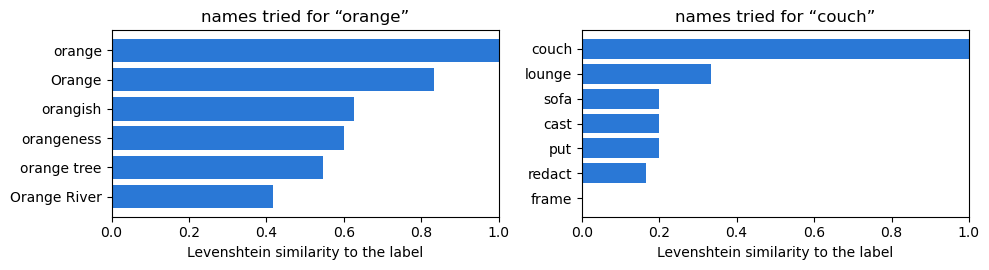

In [3]:
from pel.candidate_selection import select_candidate_names
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
for axis, label in zip(axes, ("orange", "couch")):
    names = select_candidate_names(label)
    axis.barh([n for _, n in names][::-1], [s for s, _ in names][::-1], color="#2a78d6")
    axis.set_xlim(0, 1); axis.set_xlabel("Levenshtein similarity to the label"); axis.set_title(f"names tried for “{label}”")
plt.tight_layout()

## 4.2 WordNet path similarity

**Quantities.** Synsets $s, t$; $d(s,t)$ = number of edges on the shortest path between them in the hypernym/hyponym graph.

**Purpose.** Decide whether a candidate's class is the *kind of thing* the label denotes (Algorithm 2).

$$\mathrm{sim}_{path}(s,t) = \frac{1}{1 + d(s,t)}$$

**Behaviour.** Hyperbolic decay: the first step away halves the score, later steps matter less and less.

| relation of $s$ to $t$ | $d$ | similarity |
|---|---|---|
| identical | 0 | 1 |
| parent / child | 1 | 0.5 |
| grandparent, sibling | 2 | 0.33 |
| unrelated nouns (path through the root) | ~10–20 | < 0.1 |
| different parts of speech | no path | 0 **[ours, I7]** |

**An important property:** the measure is *symmetric*. It cannot tell “$s$ is more general than $t$” from “$s$ is more specific than $t$”, and its maximum is reached when the two are the *same* concept. Remember this for Chapter 7.

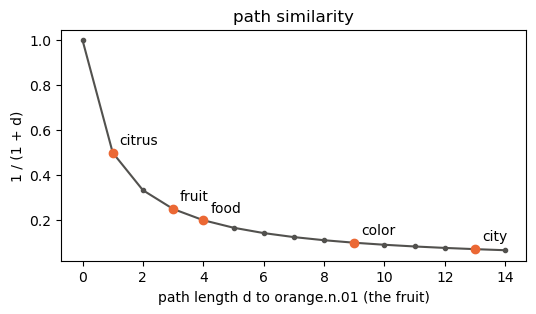

In [4]:
from pel.wordnet_access import get_synsets, path_similarity
orange = get_synsets("orange")[0]
ds = np.arange(0, 15)
plt.figure(figsize=(6, 3))
plt.plot(ds, 1 / (1 + ds), color="#52514e", marker="o", ms=3)
for word in ("citrus", "fruit", "food", "color", "city"):
    d = min(x for x in (orange.shortest_path_distance(s) for s in get_synsets(word)) if x is not None)
    plt.scatter([d], [1 / (1 + d)], color="#eb6834", zorder=3); plt.annotate(word, (d, 1 / (1 + d)), xytext=(5, 6), textcoords="offset points")
plt.xlabel("path length d to orange.n.01 (the fruit)"); plt.ylabel("1 / (1 + d)"); plt.title("path similarity");

## 4.3 The disambiguation score

**Quantities.** Label $l$ with synsets $\mathrm{Syn}(l)$; candidate $c$ whose classes in the graph have labels $\mathrm{Cls}(c)$.

$$\mathrm{score}(c) = \max_{k \in \mathrm{Cls}(c)}\; \max_{s \in \mathrm{Syn}(k)}\; \max_{t \in \mathrm{Syn}(l)}\; \mathrm{sim}_{path}(s,t)$$

**Why three maxima?** A candidate has several classes; a class label has several senses; so has the perceived label. Nothing tells the algorithm which sense is meant, so it takes the most favourable combination. This is optimistic by construction: one accidental match is enough.

**Worked example** — `orange`, with the classes WikiData actually returned:

In [5]:
from pel.recorded_access import RecordedAccess
from pel.disambiguation import class_similarity
wikidata = RecordedAccess("coco", "wikidata")
label_senses = get_synsets("orange")
rows = wikidata.retrieve("orange", "L_links")
classes = wikidata.class_labels([iri for iri, _ in rows])
descriptions = wikidata.descriptions([iri for iri, _ in rows])
for iri, links in rows:
    per_class = {k: round(class_similarity(label_senses, [k]), 2) for k in classes[iri]}
    print(f"{iri.split('/')[-1]:>10}  score {class_similarity(label_senses, classes[iri]):.2f}  {descriptions[iri][:38]:40s} {per_class}")

    Q13191  score 0.50  citrus fruit of the orange tree          {'hesperidium': 0.0, 'common name': 0.0, 'tropical fruit': 0.0, 'citrus fruit': 0.5, 'fruit': 0.33}
    Q39338  score 0.33  colour, located between red and yellow   {'red': 0.33, 'yellow': 0.33, 'secondary color': 0.0}
 Q59318527  score 0.00  eye color                                {'eye color': 0.0}
  Q3040333  score 0.25  heraldic tincture                        {'stain': 0.25, 'tincture': 0.25}
  Q7099506  score 0.12  word in the English language             {'word': 0.12}


Read the table critically. The fruit gets 0.5 through *citrus fruit*. The colour gets 0.33 — not because of anything fruit-like, but because the label also has a colour sense (`orange.n.02`) and the colour's classes *red* and *yellow* are its siblings. And once the synonyms of Algorithm 1 are included (Chapter 5), five entities named *Orange River* arrive with class *river* and score exactly 0.5 as well: WordNet lists the Orange River as a sense of “orange” (`orange.n.05`), one step below *river*. The maximum over **all** senses of the label means every sense is rewarded equally; the “physical prior” that motivates the design is not encoded in the formula, and the fruit stays first only because ties keep their previous order. **[ours]**

**Implementation.** `pel/disambiguation.py::class_similarity` is the three nested loops; `disambiguate` sorts by the score with a *stable* sort, so candidates with equal scores keep the order candidate selection gave them.

## 4.4 hit@k and its uncertainty

$$\mathrm{hit@}k = \frac{1}{|D|}\,\Bigl|\bigl\{\, l \in D : \{r_1(l),\dots,r_k(l)\} \cap GT(l) \neq \emptyset \,\bigr\}\Bigr|$$

$D$ = labels, $r_i(l)$ = the $i$-th ranked entity, $GT(l)$ = set of acceptable entities. By construction hit@1 ≤ hit@3 ≤ hit@5. (Two cells of the published Table 1 violate this — see Chapter 6.)

**Uncertainty.** Each label is a success or a failure, so hit@k is a binomial proportion $\hat p = x/n$. The Wilson score interval

$$\frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}, \qquad z = 1.96 \text{ for } 95\,\%,$$

behaves well for small $n$ and for $\hat p$ near 0 or 1. The plot shows how wide it is at the sample sizes used here:

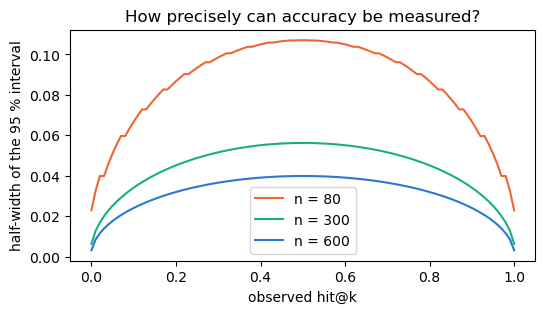

In [6]:
from pel.evaluation import wilson_interval
ps = np.linspace(0, 1, 101)
plt.figure(figsize=(6, 3))
for n, colour in ((80, "#eb6834"), (300, "#1baf7a"), (600, "#2a78d6")):
    widths = [np.diff(wilson_interval(round(p * n), n))[0] / 2 for p in ps]
    plt.plot(ps, widths, color=colour, label=f"n = {n}")
plt.xlabel("observed hit@k"); plt.ylabel("half-width of the 95 % interval"); plt.legend(); plt.title("How precisely can accuracy be measured?");

With the 80 COCO labels, accuracies are known to about ±0.10; with 300–600 Visual Genome entries, to ±0.04–0.06.

## 4.5 The paper's sample-size argument

**[paper, Sec. 5.1]** “a representative sample size of 2,328 classes is required for a 2 % margin of error and a 95 % confidence level”, out of 76,340 object classes. This is Cochran's formula with finite-population correction:

$$n_0 = \frac{z^2\,p(1-p)}{e^2}, \qquad n = \frac{n_0}{1 + \frac{n_0 - 1}{N}}, \qquad p = 0.5,\; e = 0.02,\; N = 76{,}340.$$

In [7]:
from pel.evaluation import required_sample_size
print("required sample size:", required_sample_size(population=76340, margin=0.02))

required sample size: 2328


The arithmetic reproduces exactly. **[ours]** The *assumption* behind the formula, however, is simple random sampling. The 2,399 evaluated classes are not a random sample of Visual Genome: they are the classes that have a WordNet-linked WikiData item *and* a DBpedia counterpart *and* a YAGO counterpart. Such classes are, almost by definition, the well-documented and easier ones, so accuracy on them probably over-estimates accuracy on Visual Genome at large. The margin of error describes sampling noise, not this selection effect.

**Next:** Chapter 5 walks through the code that implements all of this.